# Which Pittsburgh Neighborhood Has the Cleanest Air?
### My submetric: Air Quality

## 1. Introduction
Our group is picking the "best" neighborhood in Pittsburgh. For my individual submetric I chose air quality. Pollution affects respiratory and cardiovascular health and day-to-day quality of life, so a neighborhood with cleaner air is, all else equal, a better place to live.

**What is AQI?** The Air Quality Index is a number from the county's air monitors. **Lower is cleaner.**

| AQI | Meaning |
|---|---|
| 0 to 50 | Good |
| 51 to 100 | Moderate |

**Data:** [Allegheny County Air Quality, Daily AQI (WPRDC)](https://data.wprdc.org/dataset/allegheny-county-air-quality/resource/4ab1e23f-3262-4bd3-adbf-f72f0119108b)

## 2. The Metric: "grading on a curve"
**My first idea didn't work.** I averaged every AQI number at each monitor. But monitors measure *different* pollutants, and some pollutants naturally have bigger numbers. 
**My fix was to grade on a curve.** Each day, I compare a neighborhood to the *rest of the county on that same day*, using the same pollutant.

> **Neighborhood AQI minus county AQI (same day). Below 0 means cleaner than the rest of the county.**

I use the two particle pollutants, **PM2.5 and PM10** (tiny bits of dust and smoke that people breathe in), because the city monitors measure them.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Air_Quality.csv", parse_dates=["date"])

#PM2.5 shows up under several codes (PM25, PM25B, PM25T...), so group them by name
def family(p):
    return "PM25" if p.startswith("PM25") else "PM10" if p.startswith("PM10") else p

df["family"] = df["parameter"].apply(family)
df = df[df["family"].isin(["PM25", "PM10"])]   #keep only the two particle pollutants

### Which air monitors are inside Pittsburgh?
Most monitors are in other towns (Clairton, Avalon, and so on). I matched each monitor's map location to the City of Pittsburgh neighborhood outlines. **Only these four are inside the city**, covering three neighborhoods.

*(Locations come from the Allegheny County Health Department 2018 Annual Network Plan. The monitor named "Pittsburgh" isn't labeled in that plan, so I assumed it is the Manchester monitor.)*

In [10]:
site_to_hood = {
    "Lawrenceville":   "Lower Lawrenceville",
    "Lawrenceville 2": "Lower Lawrenceville",
    "Flag Plaza":      "Crawford-Roberts",
    "Pittsburgh":      "Manchester",   #assumed
}

In [5]:
#one number per site, per day, per pollutant
daily = df.groupby(["date", "family", "site"], as_index=False)["index_value"].mean()

#total and count across ALL monitors each day (so we can get the average of the others)
totals = daily.groupby(["date", "family"])["index_value"].agg(total="sum", n="count").reset_index()

mine = daily[daily["site"].isin(site_to_hood)].merge(totals, on=["date", "family"])
mine = mine[mine["n"] > 1].copy()
mine["hood"] = mine["site"].map(site_to_hood)

#county average of the OTHER monitors = (total - mine) / (n - 1)
mine["county_avg"] = (mine["total"] - mine["index_value"]) / (mine["n"] - 1)
mine["rel_AQI"] = mine["index_value"] - mine["county_avg"]   #below 0 = cleaner than the county

### One example day

In [6]:
ex = mine[(mine["hood"] == "Crawford-Roberts") & (mine["date"] >= "2019-07-01")].iloc[0]
print(f"On {ex['date'].date()}, Crawford-Roberts had a PM10 AQI of {ex['index_value']:.0f}.")
print(f"The other monitors in the county averaged {ex['county_avg']:.1f} that day.")
print(f"Difference: {ex['rel_AQI']:+.1f}  ({'cleaner' if ex['rel_AQI'] < 0 else 'dirtier'} than the county)")
print("\nI repeat this for every day, then average.")

On 2019-07-01, Crawford-Roberts had a PM10 AQI of 17.
The other monitors in the county averaged 25.0 that day.
Difference: -8.0  (cleaner than the county)

I repeat this for every day, then average.


## 3. The Best Neighborhood
Average all the daily differences for each neighborhood, then turn them into a **0 to 1 score** (1 = cleanest) so my group can combine it with the other metrics.

In [7]:
per_pollutant = mine.groupby(["hood", "family"])["rel_AQI"].agg(["mean", "count"])
result = per_pollutant.groupby("hood").agg(rel_AQI=("mean", "mean"), days=("count", "sum")).round(2)
result = result.sort_values("rel_AQI")

#0-1 score: 1 = cleanest, 0 = dirtiest
lo, hi = result["rel_AQI"].min(), result["rel_AQI"].max()
result["air_score"] = ((hi - result["rel_AQI"]) / (hi - lo)).round(2)

result.to_csv("Air_Quality_Scores.csv")   # file to share with my group
result

,rel_AQI,days,air_score
hood,,,
Crawford-Roberts,-5.25,2239,1.00
Manchester,-1.63,4203,0.22
Lower Lawrenceville,-0.63,1557,0.00


### The chart: how much cleaner than the rest of the county?

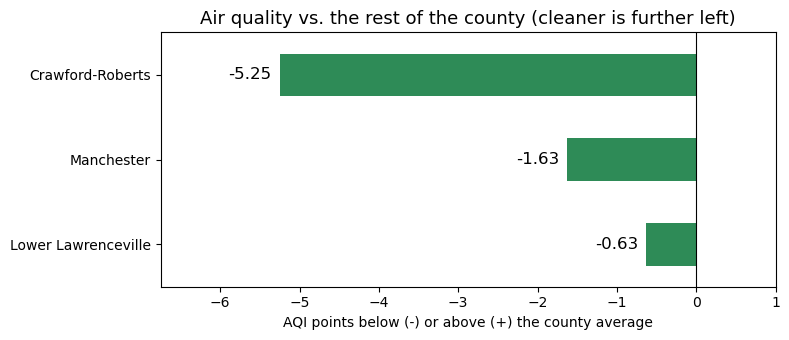

In [8]:
colors = ["#2e8b57" if v < 0 else "#c0392b" for v in result["rel_AQI"]]   # green = cleaner

ax = result["rel_AQI"].plot(kind="barh", color=colors, figsize=(8, 3.5))
for i, v in enumerate(result["rel_AQI"]):
    ax.text(v - 0.1, i, f"{v:+.2f}", va="center", ha="right", fontsize=12)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(result["rel_AQI"].min() - 1.5, 1)
ax.set_title("Air quality vs. the rest of the county (cleaner is further left)", fontsize=13)
ax.set_xlabel("AQI points below (-) or above (+) the county average")
ax.set_ylabel("")
ax.invert_yaxis()   #cleanest on top
plt.tight_layout()
plt.show()

**How to read it:** every neighborhood is *below* 0, so all three had cleaner air than the county average. **The longer the bar, the cleaner the air.** Crawford-Roberts is the cleanest because it has the longest bar.

**Important Limits:**
- Only neighborhoods with an air monitor could be scored, which is just three.
- They aren't measured on exactly the same pollutants or years (Crawford-Roberts: PM10 only, 2016 to early 2022; Lower Lawrenceville: PM2.5 only, mostly 2016 to 2020; Manchester: both, 2020 to now). Comparing each to the county on the same days helps, but it isn't perfect.
- The differences are a few AQI points, so this is a *relative* ranking, not a big gap in health.

## 4. Conclusion
